# REGRESION LINEAL SIMPLE


# Carga de datos
Importamos las librerías necesarias y cargamos el archivo Excel en un DataFrame. Con `head()` comprobamos que los datos se han leído correctamente.

In [2]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from pathlib import Path

# Ruta del archivo de datos
DATA_PATH = Path(r"C:\Users\lenovo\Desktop\BDATA2\RETO5\datos\datos_limpio_automovil.xlsx")

data_lin_regre = pd.read_excel(DATA_PATH)
data_lin_regre.head()

,Unnamed: 0,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,...,Estudios_Escolar,Estudios_Grado Universitario,Estudios_Máster,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero
0,0,O77MPJ,26,19153,6973,706,9,1,19.05,36,...,False,True,False,False,False,True,False,False,False,True
1,8,IYOL1S,29,39531,40000,826,0,1,9.74,24,...,False,False,False,False,False,True,False,True,False,False
2,9,FRMZVN,29,40348,16448,740,9,1,14.73,24,...,False,False,True,False,False,True,False,False,False,True
3,26,YKHXVY,38,41732,42040,661,173,2,13.24,48,...,False,True,False,False,False,False,True,True,False,False
4,32,NHDJTK,35,35085,16406,759,181,1,9.74,36,...,True,False,False,False,False,True,False,True,False,False


###  Análisis exploratorio
Un diagrama de dispersión permite ver a simple vista si existe relación entre las variables, si es lineal y si hay valores atípicos.


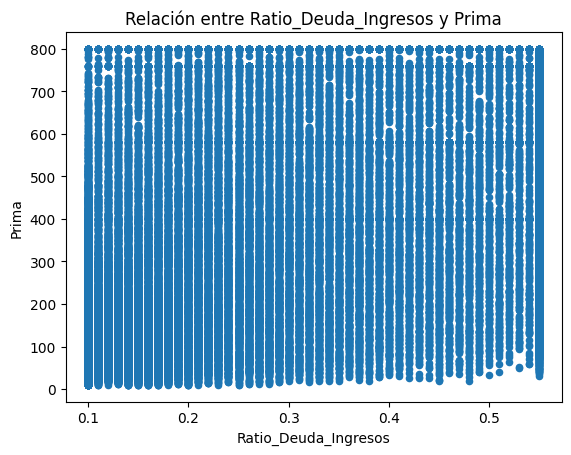

In [3]:
data_lin_regre.plot(x="Ratio_Deuda_Ingresos", y="Prima", kind="scatter")
plt.title("Relación entre Ratio_Deuda_Ingresos y Prima")
plt.xlabel("Ratio_Deuda_Ingresos")
plt.ylabel("Prima")
plt.show()

### INTERPRETACIÓN
- `Ratio_Deuda_Ingresos` toma valores discretos entre 0.10 y 0.55, por eso los puntos forman columnas verticales.
- En cada valor del ratio la prima abarca casi todo el rango (de ~10 a 800), así que hay **mucha dispersión** y los puntos se solapan (con más de 76 000 observaciones es difícil ver la tendencia a simple vista).
- La prima parece tener un **límite superior en 800** (muchas observaciones apiladas en ese valor).
- No se aprecian outliers extremos; la relación, si existe, es débil-moderada y hay que confirmarla con la correlación.

### Calculamos la correlación y su significancia estadística

El coeficiente de Pearson mide la **fuerza y dirección de la relación lineal** (de -1 a 1). El test contrasta:
- **H0:** no hay correlación lineal (ρ = 0)
- **H1:** sí hay correlación lineal (ρ ≠ 0)



In [ ]:
from scipy.stats import pearsonr

corr_test = pearsonr(
    x=data_lin_regre["Ratio_Deuda_Ingresos"],
    y=data_lin_regre["Prima"]
)

print(f"Coeficiente de correlación de Pearson: {corr_test.statistic:.4f}")
print(f"P-value: {corr_test.pvalue:.4g}")

Coeficiente de correlación de Pearson: 0.6355
P-value: 0


**Resultado:** r = 0.6355 y p-value ≈ 0.

**Conclusión:** se rechaza H0. Existe una correlación lineal **positiva y de intensidad moderada-alta**: a mayor ratio deuda/ingresos, mayor prima. (Con una muestra tan grande casi cualquier correlación sería significativa, así que lo relevante es el tamaño de r, no el p-value.)

### DIVISION DE LOS DATOS EN TRAIN TEST

Separamos los datos en **80 % para entrenar** y **20 % para evaluar**. Así medimos la capacidad predictiva del modelo con datos que no ha visto. Se fija `random_state=42` para que los resultados sean reproducibles.

In [5]:
from sklearn.model_selection import train_test_split

X = data_lin_regre[["Ratio_Deuda_Ingresos"]]
y = data_lin_regre[["Prima"]]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.8,
    random_state=42,
    shuffle=True
)

print(f"Observaciones de entrenamiento: {len(X_train)}")
print(f"Observaciones de test: {len(X_test)}")

Observaciones de entrenamiento: 61539
Observaciones de test: 15385


### Creación del modelo con la librería SCIKIT LEARN

In [ ]:
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    root_mean_squared_error,
    mean_squared_error,
    mean_absolute_error
)

modelo = LinearRegression()
modelo.fit(X=X_train, y=y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [7]:
 #Información del modelo

print(f"Intercept: {modelo.intercept_[0]:.4f}")
print(f"Coeficiente: {modelo.coef_[0][0]:.4f}")
print(f"R^2 de train: {modelo.score(X_train, y_train):.4f}")
print(f"R^2 de test: {modelo.score(X_test, y_test):.4f}")

print("\nEcuación estimada:")
print(
    f"Prima = {modelo.intercept_[0]:.4f} + "
    f"{modelo.coef_[0][0]:.4f} * Ratio_Deuda_Ingresos"
)

Intercept: 82.9630
Coeficiente: 940.2430
R^2 de train: 0.4063
R^2 de test: 0.3944

Ecuación estimada:
Prima = 82.9630 + 940.2430 * Ratio_Deuda_Ingresos



**Interpretación:**
- **Intercepto (≈ 82.96):** prima esperada cuando el ratio es 0. Es un valor teórico, porque el ratio real solo va de 0.10 a 0.55 (extrapolación).
- **Pendiente (≈ 940.24):** por cada aumento de 1 unidad en el ratio la prima sube en promedio 940. Como el ratio varía en rangos pequeños, es más intuitivo decir que **+0.10 en el ratio supone unos +94 de prima**.
- **R² de train (≈ 0.406):** el modelo explica alrededor del **41 %** de la variabilidad de la prima, que es lo esperable con r = 0.6355 (r² = 0.404). El R² de test debe ser parecido; si lo es, no hay sobreajuste (se verá al ejecutar esta celda corregida).
- **Ecuación:** Prima ≈ 82.96 + 940.24 · Ratio_Deuda_Ingresos

### Una vez entrenado el modelo, se evalúa su capacidad predictiva empleando el conjunto de test

Calculamos las métricas de error sobre el conjunto de test:
- **MSE:** error cuadrático medio.
- **RMSE:** raíz del MSE, en las mismas unidades que la prima.
- **MAE:** error absoluto medio, menos sensible a valores extremos.



In [8]:
# Error de test del modelo

predicciones_test = modelo.predict(X=X_test)

mse = mean_squared_error(y_true=y_test, y_pred=predicciones_test)
rmse = root_mean_squared_error(y_true=y_test, y_pred=predicciones_test)
mae = mean_absolute_error(y_true=y_test, y_pred=predicciones_test)

print(f"Primeras cinco predicciones: {predicciones_test[:5].ravel()}")
print(f"El error (MSE) de test es: {mse:.2f}")
print(f"El error (RMSE) de test es: {rmse:.2f}")
print(f"El error (MAE) de test es: {mae:.2f}")

Primeras cinco predicciones: [318.02373289 176.98728081 374.43831372 600.09663704 487.26747538]
El error (MSE) de test es: 43425.13
El error (RMSE) de test es: 208.39
El error (MAE) de test es: 169.55


**Resultados:** MSE = 43 425.13, RMSE = 208.39, MAE = 169.55.

**Conclusión:** en promedio, el modelo se equivoca en unas **170 unidades de prima** (MAE), y las desviaciones grandes pesan hasta ~208 (RMSE). Teniendo en cuenta que la prima va de ~10 a 800, el error es **considerable**: el ratio por sí solo no basta para predecir la prima con precisión. Las primeras predicciones (entre ~177 y ~600) se quedan en un rango muy estrecho comparado con el real.

### CREACION DEL MODELO CON STATSMODELS


#### Creación del modelo utilizando matrices como en Scikit-learn

Repetimos el ajuste con `statsmodels`, que aporta **inferencia estadística**: errores estándar, contrastes t, p-values e intervalos de confianza. Hay que añadir la constante manualmente con `add_constant`.



In [ ]:
# Se crea una copia para añadir la constante sin modificar X_train original.
X_train_sm = sm.add_constant(X_train, prepend=True)

modelo_sm = sm.OLS(endog=y_train, exog=X_train_sm)
modelo_sm = modelo_sm.fit()

print(modelo_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Prima   R-squared:                       0.406
Model:                            OLS   Adj. R-squared:                  0.406
Method:                 Least Squares   F-statistic:                 4.212e+04
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:14:50   Log-Likelihood:            -4.1518e+05
No. Observations:               61539   AIC:                         8.304e+05
Df Residuals:                   61537   BIC:                         8.304e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   82.9630 

**Lectura del summary:**
- `coef`: const = 82.96 y Ratio_Deuda_Ingresos = 940.24, idénticos a scikit-learn.
- `P>|t|` = 0.000 en ambos: los dos coeficientes son **estadísticamente significativos** (t = 205 para la pendiente).
- `R-squared` = 0.406 (igual que Adj. R²): el modelo explica el 40.6 % de la variabilidad.
- `F-statistic` = 42 120 con Prob(F) = 0: el modelo es globalmente significativo.
- `Durbin-Watson` = 1.99, muy cerca de 2: **no hay autocorrelación** de los residuos.
- `Cond. No.` = 6.10: sin problemas de multicolinealidad (con una sola variable no era de esperar).
- `Skew` = 0.28 y `Kurtosis` = 2.82: ligera asimetría positiva y colas algo más ligeras que una normal; `Omnibus` y `Jarque-Bera` con p ≈ 0 apuntan a que los residuos no son normales (se analiza en el apartado 7).

#### Intervalos de confianza de los coeficientes

In [10]:
intervalos_ci = modelo_sm.conf_int(alpha=0.05)
intervalos_ci.columns = ["2.5%", "97.5%"]
intervalos_ci

,2.5%,97.5%
const,79.660168,86.265791
Ratio_Deuda_Ingresos,931.262998,949.223029


Con un 95 % de confianza:
- **Intercepto:** entre 79.66 y 86.27.
- **Pendiente:** entre 931.26 y 949.22.

El intervalo de la pendiente es estrecho y **no incluye el 0**, por lo que el efecto es significativo y está estimado con mucha precisión (por el gran tamaño de la muestra).

#### Predicciones

In [11]:
# Predicciones con intervalo de confianza del 95%

predicciones = modelo_sm.get_prediction(
    exog=X_train_sm
).summary_frame(alpha=0.05)

predicciones.head(4)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
38282,289.816442,0.948375,287.957626,291.675259,-113.850329,693.483214
69182,176.987281,1.306059,174.427401,179.547161,-226.683327,580.657889
24847,412.048034,0.841463,410.398765,413.697303,8.382174,815.713895
34694,600.096637,1.341305,597.467677,602.725597,196.425585,1003.767689


Para cada observación obtenemos la predicción (`mean`), su error estándar y los intervalos al 95 %:
- `mean_ci_*`: intervalo de confianza de la **media** de la prima para ese ratio (muy estrecho, p. ej. 287.96–291.68 para la primera observación).
- `obs_ci_*`: intervalo de **predicción** para una observación individual (muy ancho, p. ej. de -113.9 a 693.5), porque incluye la dispersión individual.

Esa diferencia refleja que conocemos bien la tendencia media, pero no podemos predecir con precisión la prima de un cliente concreto. Además, algunos límites inferiores salen **negativos**, algo imposible para una prima.

#### Representación gráfica del modelo

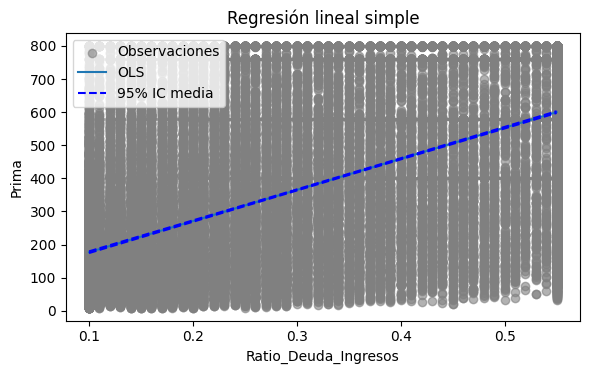

In [12]:
# Predicciones con intervalo de confianza del 95%

predicciones = modelo_sm.get_prediction(
    exog=X_train_sm
).summary_frame(alpha=0.05)

predicciones["x"] = X_train["Ratio_Deuda_Ingresos"].values
predicciones["y"] = y_train["Prima"].values
predicciones = predicciones.sort_values("x")

# Gráfico del modelo

fig, ax = plt.subplots(figsize=(6, 3.84))

ax.scatter(
    predicciones["x"],
    predicciones["y"],
    marker="o",
    color="gray",
    alpha=0.6,
    label="Observaciones"
)

ax.plot(
    predicciones["x"],
    predicciones["mean"],
    linestyle="-",
    label="OLS"
)

ax.plot(
    predicciones["x"],
    predicciones["mean_ci_lower"],
    linestyle="--",
    color="blue",
    label="95% IC media"
)

ax.plot(
    predicciones["x"],
    predicciones["mean_ci_upper"],
    linestyle="--",
    color="blue"
)

ax.set_title("Regresión lineal simple")
ax.set_xlabel("Ratio_Deuda_Ingresos")
ax.set_ylabel("Prima")
ax.legend()

plt.tight_layout()
plt.show()

Observaciones (puntos grises), recta ajustada y bandas al 95 %.

**Observación:**
- La recta tiene pendiente positiva: la prima media pasa de ~177 (ratio 0.10) a ~600 (ratio 0.55).
- La banda de la media es tan estrecha que casi se confunde con la recta.
- La banda de predicción individual es muy ancha (más de 800 unidades de amplitud) y llega a valores negativos, es decir, **el ajuste es modesto pese a ser significativo**: la nube de puntos cubre casi todo el rango en cada nivel del ratio.

#### Error del test


In [13]:
# Error de test del modelo

X_test_sm = sm.add_constant(X_test, prepend=True)
predicciones_test_sm = modelo_sm.predict(X_test_sm)

rmse_test = root_mean_squared_error(
    y_true=y_test,
    y_pred=predicciones_test_sm
)

mae_test = mean_absolute_error(
    y_true=y_test,
    y_pred=predicciones_test_sm
)

print(f"El error (RMSE) de test es: {rmse_test:.2f}")
print(f"El error (MAE) de test es: {mae_test:.2f}")

El error (RMSE) de test es: 208.39
El error (MAE) de test es: 169.55


Evaluamos el modelo de statsmodels sobre el conjunto de test. El RMSE obtenido (208.39) coincide con el de scikit-learn, como era de esperar porque es el mismo modelo.

In [14]:
print(modelo_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Prima   R-squared:                       0.406
Model:                            OLS   Adj. R-squared:                  0.406
Method:                 Least Squares   F-statistic:                 4.212e+04
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:14:53   Log-Likelihood:            -4.1518e+05
No. Observations:               61539   AIC:                         8.304e+05
Df Residuals:                   61537   BIC:                         8.304e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   82.9630 

## Validación de los supuestos
La inferencia de la regresión lineal es fiable solo si se cumplen:
1. **Linealidad** entre X e y.
2. **Independencia** de los residuos.
3. **Homocedasticidad** (varianza constante de los residuos).
4. **Normalidad** de los residuos.

## COMPROBACION DE LOS SUPUESTOS DEL MODELO

### Diagnóstico de los resíduos

Residuo = valor predicho − valor observado.

In [15]:
# Diagnóstico de los errores (residuos) de las predicciones de entrenamiento

prediccion_train = modelo_sm.predict(X_train_sm)
residuos_train = prediccion_train - y_train["Prima"].values

# Los residuos se calculan como:
# Residuo = valor predicho - valor observado

In [16]:
residuos_train

38282   -470.183558
69182   -602.692719
24847    294.938034
34694   -159.903363
74866    144.757281
            ...    
6265     -50.162719
54886   -159.903363
76820   -273.171407
860     -199.903363
15795     35.939432
Length: 61539, dtype: float64

In [17]:
prediccion_train

38282    289.816442
69182    176.987281
24847    412.048034
34694    600.096637
74866    176.987281
            ...    
6265     176.987281
54886    600.096637
76820    336.828593
860      600.096637
15795    223.999432
Length: 61539, dtype: float64

In [18]:
y_train

,Prima
38282,760.00
69182,779.68
24847,117.11
34694,760.00
74866,32.23
...,...
6265,227.15
54886,760.00
76820,610.00
860,800.00


### Inspección visual

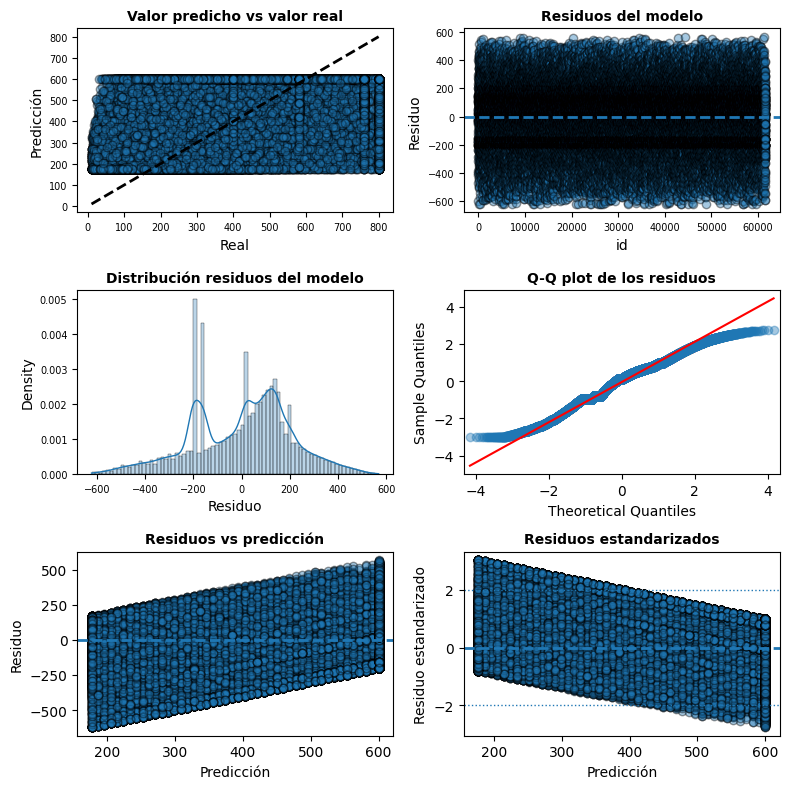

In [19]:
import seaborn as sns

# Gráficos

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(8, 8))

# Relación entre los valores reales y los predichos
axes[0, 0].scatter(
    y_train["Prima"],
    prediccion_train,
    edgecolors=(0, 0, 0),
    alpha=0.4
)
axes[0, 0].plot(
    [y_train["Prima"].min(), y_train["Prima"].max()],
    [y_train["Prima"].min(), y_train["Prima"].max()],
    "k--",
    lw=2
)
axes[0, 0].set_title("Valor predicho vs valor real", fontsize=10, fontweight="bold")
axes[0, 0].set_xlabel("Real")
axes[0, 0].set_ylabel("Predicción")
axes[0, 0].tick_params(labelsize=7)

# Residuos en el orden de las observaciones
axes[0, 1].scatter(
    range(len(residuos_train)),
    residuos_train,
    edgecolors=(0, 0, 0),
    alpha=0.4
)
axes[0, 1].axhline(y=0, linestyle="--", lw=2)
axes[0, 1].set_title("Residuos del modelo", fontsize=10, fontweight="bold")
axes[0, 1].set_xlabel("id")
axes[0, 1].set_ylabel("Residuo")
axes[0, 1].tick_params(labelsize=7)

# Histograma de residuos
sns.histplot(
    data=residuos_train,
    stat="density",
    kde=True,
    line_kws={"linewidth": 1},
    alpha=0.3,
    ax=axes[1, 0]
)
axes[1, 0].set_title(
    "Distribución residuos del modelo",
    fontsize=10,
    fontweight="bold"
)
axes[1, 0].set_xlabel("Residuo")
axes[1, 0].tick_params(labelsize=7)

# Q-Q plot
sm.qqplot(
    residuos_train,
    fit=True,
    line="q",
    ax=axes[1, 1],
    alpha=0.4,
    lw=1
)
axes[1, 1].set_title(
    "Q-Q plot de los residuos",
    fontsize=10,
    fontweight="bold"
)

# Residuos frente a valores predichos
axes[2, 0].scatter(
    prediccion_train,
    residuos_train,
    edgecolors=(0, 0, 0),
    alpha=0.4
)
axes[2, 0].axhline(y=0, linestyle="--", lw=2)
axes[2, 0].set_title(
    "Residuos vs predicción",
    fontsize=10,
    fontweight="bold"
)
axes[2, 0].set_xlabel("Predicción")
axes[2, 0].set_ylabel("Residuo")

# Residuos estandarizados
residuos_estandarizados = modelo_sm.get_influence().resid_studentized_internal

axes[2, 1].scatter(
    prediccion_train,
    residuos_estandarizados,
    edgecolors=(0, 0, 0),
    alpha=0.4
)
axes[2, 1].axhline(y=0, linestyle="--", lw=2)
axes[2, 1].axhline(y=2, linestyle=":", lw=1)
axes[2, 1].axhline(y=-2, linestyle=":", lw=1)
axes[2, 1].set_title(
    "Residuos estandarizados",
    fontsize=10,
    fontweight="bold"
)
axes[2, 1].set_xlabel("Predicción")
axes[2, 1].set_ylabel("Residuo estandarizado")

plt.tight_layout()
plt.show()

- **Predicho vs real:** los puntos están lejos de la diagonal. Las predicciones solo ocupan el rango ~177–600 mientras que la prima real llega hasta 800 (y baja a ~10), es decir, el modelo **no capta los valores extremos**.
- **Residuos por observación:** nube de puntos sin tendencia alrededor de 0, coherente con la **independencia** (Durbin-Watson = 1.99).
- **Histograma de residuos:** distribución **no normal**, con picos marcados (en torno a -180 y 0) y cola derecha más larga. Esos picos provienen de que muchas observaciones tienen exactamente la misma prima (por ejemplo, 760 u 800), lo que genera residuos repetidos.
- **Q-Q plot:** forma de "S"; los puntos se separan de la recta en ambas colas, que son más **ligeras** que las de una normal (kurtosis 2.82 < 3), lo que es típico de una variable acotada.
- **Residuos vs predicción:** forma de paralelogramo inclinado, sin embudo claro (la amplitud es aproximadamente constante), pero con una ligera pendiente positiva debido al límite superior/inferior de la prima. No hay curvatura evidente, por lo que **la linealidad es aceptable**; la homocedasticidad se cumple aproximadamente.
- **Residuos estandarizados:** este panel no aparece en la salida guardada (esa figura tiene 5 gráficos). Al volver a ejecutar la celda, revisa cuántos puntos superan ±2: serán los posibles atípicos..

### TEST de NORMALIDAD

- **H0:** los residuos siguen una distribución normal.
- **H1:** no la siguen.

Se aplican **Shapiro-Wilk** y **D'Agostino-Pearson**. Si p < 0.05 se rechaza la normalidad.



In [20]:
from scipy import stats

# Normalidad de los residuos: Shapiro-Wilk
shapiro_test = stats.shapiro(residuos_train)

print(f"Estadístico Shapiro-Wilk: {shapiro_test.statistic:.4f}")
print(f"p-value: {shapiro_test.pvalue:.4g}")

if shapiro_test.pvalue < 0.05:
    print("Conclusión: se rechaza H0. Hay evidencia de que los residuos no siguen una distribución normal.")
else:
    print("Conclusión: no se rechaza H0. No hay evidencia suficiente para afirmar que los residuos no sean normales.")

Estadístico Shapiro-Wilk: 0.9871
p-value: 1.123e-55
Conclusión: se rechaza H0. Hay evidencia de que los residuos no siguen una distribución normal.


c:\Users\lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 61539.
  res = hypotest_fun_out(*samples, **kwds)


In [21]:
k2, p_value = stats.normaltest(residuos_train)

print(f"Estadístico = {k2:.4f}")
print(f"p-value = {p_value:.4g}")



Estadístico = 854.5989
p-value = 2.668e-186



- Shapiro-Wilk: p-value ≈ 0 (scipy avisa de que con N > 5000 el p-value puede no ser exacto; aquí N = 61 539).
- D'Agostino-Pearson: estadístico = 854.60, p-value = 2.7e-186.

**Conclusión:** en ambos casos se **rechaza H0**: los residuos **no son normales**, lo que concuerda con el histograma multimodal y el Q-Q plot en forma de S. Con una muestra tan grande, los tests detectan incluso desviaciones pequeñas, pero aquí la no normalidad es visible también en los gráficos. Aun así, por el tamaño muestral, las estimaciones e intervalos de los coeficientes siguen siendo razonablemente fiables (teorema central del límite); lo que **no** son fiables son los intervalos de predicción individual.

###  Conclusiones
- Existe una relación **positiva y significativa** entre el ratio deuda/ingresos y la prima (r = 0.6355, p ≈ 0).
- El modelo estimado es **Prima ≈ 82.96 + 940.24 · Ratio_Deuda_Ingresos**: un aumento de 0.10 en el ratio equivale a unos 94 de prima.
- El modelo explica solo el **40.6 %** de la variabilidad de la prima (R² = 0.406); el error de test es RMSE = 208.39 y MAE = 169.55, un error alto frente al rango de la prima (~10–800).
- **Supuestos:** hay independencia (DW = 1.99), la linealidad es aceptable y la homocedasticidad se cumple aproximadamente, pero los **residuos no son normales** (Shapiro-Wilk y D'Agostino-Pearson rechazan H0), por la prima acotada y los valores repetidos.
- **Limitaciones y mejoras:** el modelo no capta los valores extremos de la prima ni evita predicciones/intervalos negativos. Conviene añadir más variables (regresión múltiple: edad, ingresos, scoring…), considerar transformaciones de la variable respuesta o modelos para variables acotadas.